In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_fqe_final_seeds as fqe_ope

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [2]:
# --- run folders: fill in the two HS ones from your sweep notebook ---
cql_hs_dir   = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep"      # root of the HS CQL alpha sweep
sarsa_hs_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds"      # root of the HS SARSA critics (seeds 0-4)
fqe_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/fqe/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_only"

# Session-only fallback; not needed once the runs.py edit is in
if "fqe" not in R.FAMILIES:
    R.register_family(R.FamilySpec(name="fqe", detect=R._path_contains("fqe")))

ALPHA = 0.029
cql_study   = R.make_study(cql_hs_dir, family="cql", group_by=(),
                           include=lambda r: r.get("cql_alpha") is not None and abs(r.get("cql_alpha") - ALPHA) < 1e-9)
sarsa_study = R.make_study(sarsa_hs_dir, family="sarsa", group_by=())
fqe_study   = R.make_study(fqe_dir, family="fqe", group_by=())

cql_final    = M.load_study_models(cql_study)[()]       # {seed: LoadedModel}, alpha = 0.029 only
sarsa_models = M.load_study_models(sarsa_study)          # {(): {seed: LoadedModel}}
fqe_models   = M.load_study_models(fqe_study)            # {(): {seed: LoadedModel}}

assert sorted(cql_final) == sorted(fqe_models[()]) == sorted(sarsa_models[()]) == [0, 1, 2, 3, 4], \
    (sorted(cql_final), sorted(fqe_models[()]), sorted(sarsa_models[()]))

store = D.DataStore(keep=("train", "val"))
print(fqe_study.table())

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/fqe/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_only:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is F

In [3]:
for seed, m in sorted(fqe_models[()].items()):
    print(seed, "|", m.record.data_identity.short())
    print("   target-policy hints:", fqe_ope.target_policy_hints(m))
    print("   discount/reward:", {k: m.record.get(k) for k in fqe_ope.REWARD_DEFINING_KEYS})
print(sorted(fqe_models[()][0].record.hyperparams))

print("CQL :", {k: cql_final[0].record.get(k) for k in fqe_ope.REWARD_DEFINING_KEYS})
print("SARSA:", {k: sarsa_models[()][0].record.get(k) for k in fqe_ope.REWARD_DEFINING_KEYS})

0 | state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]
   target-policy hints: {}
   discount/reward: {'discount': 0.975, 'terminal_discount': 0.998, 'reward_type': 'health_score', 'health_score_scale': 0.0, 'health_score_hourly_change_scale': 1.0, 'total_health_score_scale': 1.0, 'terminal_reward_scale': 10.0, 'health_score_hourly_change_clip': 100.0, 'actions_shift': True}
1 | state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]
   target-policy hints: {}
   discount/reward: {'discount': 0.975, 'terminal_discount': 0.998, 'reward_type': 'health_score', 'health_score_scale': 0.0, 'health_score_hourly_change_scale': 1.0, 'total_health_score_scale': 1.0, 'terminal_reward_scale': 10.0, 'health_score_hourly_change_clip': 100.0, 'actions_shift': True}
2 | state seed 2, shared reward [choc_dynamic_deephit_tran

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:143: UserWarning: seed 0: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: V_pi 0.20 [0.13, 0.28]  adv1 0.046  V_mu -0.18  dV 0.384 [0.326, 0.444]  occupancy 0.987
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:143: UserWarning: seed 1: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: V_pi 0.43 [0.35, 0.51]  adv1 0.070  V_mu -0.19  dV 0.623 [0.566, 0.684]  occupancy 0.984
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


...

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 3: V_pi 0.56 [0.48, 0.63]  adv1 0.066  V_mu -0.05  dV 0.609 [0.541, 0.678]  occupancy 0.989
  building processors for state seed 4, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:143: UserWarning: seed 4: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  warnings.warn(f"{fqe.record.label}: cannot verify which CQL model this FQE was trained against "


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 4: V_pi 0.39 [0.30, 0.49]  adv1 0.063  V_mu -0.16  dV 0.544 [0.467, 0.627]  occupancy 0.974

Pairing (CQL seed <-> FQE seed):
 seed                                                                                                                                                                                                                                                                                                                    cql_run                                                                                                                                                                                                                                                                         fqe_run fqe_target_hint                                                 check 

,seed,alpha,n_rows,n_stays,V_pi,V_pi_lo,V_pi_hi,adv1,adv1_lo,adv1_hi,...,adv_all_norm,frac_adv_pos,fqe_q_iqr,V_mu,V_mu_lo,V_mu_hi,dV,dV_lo,dV_hi,occupancy
0,0,0.029,116662,310,0.204,0.133,0.276,0.046,0.029,0.061,...,0.088,0.731,0.950,-0.180,-0.254,-0.109,0.384,0.326,0.444,0.987
1,1,0.029,116662,310,0.429,0.349,0.509,0.070,0.052,0.091,...,0.093,0.763,0.862,-0.195,-0.264,-0.124,0.623,0.566,0.684,0.984
2,2,0.029,116662,310,0.152,0.094,0.212,0.038,0.020,0.055,...,0.083,0.705,0.741,-0.135,-0.202,-0.068,0.286,0.231,0.341,0.991
3,3,0.029,116662,310,0.556,0.478,0.634,0.066,0.050,0.083,...,0.090,0.767,0.978,-0.053,-0.115,0.007,0.609,0.541,0.678,0.989
4,4,0.029,116662,310,0.389,0.298,0.487,0.063,0.044,0.081,...,0.090,0.777,1.087,-0.156,-0.232,-0.082,0.544,0.467,0.627,0.974


,mean,min,max,std,seeds_with_CI_above_0
V_pi,0.346,0.152,0.556,0.166,NaN
V_mu,-0.144,-0.195,-0.053,0.055,NaN
dV,0.490,0.286,0.623,0.148,5.0
adv1,0.056,0.038,0.070,0.014,5.0
adv_all_norm,0.089,0.083,0.093,0.004,NaN
frac_adv_pos,0.748,0.705,0.777,0.030,NaN
occupancy,0.985,0.974,0.991,0.007,NaN


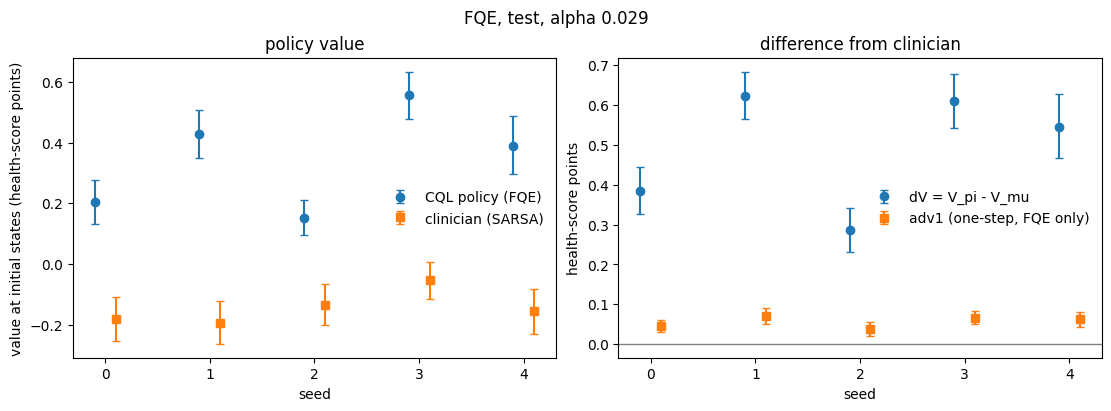

In [4]:
store_test = D.DataStore(keep=("train", "test"))      # train for the occupancy table, test for the evaluation
ope_test = fqe_ope.run_fqe_ope(cql_final, fqe_models, store_test, sarsa_models=sarsa_models,
                               split="test", n_severity_bins=200)
display(ope_test.round(3))
display(fqe_ope.summarize_fqe(ope_test).round(3))
fqe_ope.plot_fqe_ope(ope_test, title="FQE, test, alpha 0.029");

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 0: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  # Per-seed OPE


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: V_pi 0.20 [0.13, 0.28]  adv1 0.046  V_mu -0.18  dV 0.384 [0.326, 0.444]  occupancy 0.987
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 1: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  # Per-seed OPE


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: V_pi 0.43 [0.35, 0.51]  adv1 0.070  V_mu -0.19  dV 0.623 [0.566, 0.684]  occupancy 0.984
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


...

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 3: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  # Per-seed OPE


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 3: V_pi 0.56 [0.48, 0.63]  adv1 0.066  V_mu -0.05  dV 0.609 [0.541, 0.678]  occupancy 0.989
  building processors for state seed 4, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_fqe_final_seeds.py:150: UserWarning: seed 4: cannot verify which CQL model this FQE was trained against (no target-policy path in its hyperparameters). Confirm from the training log.
  # Per-seed OPE


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 4: V_pi 0.39 [0.30, 0.49]  adv1 0.063  V_mu -0.16  dV 0.544 [0.467, 0.627]  occupancy 0.974

Pairing (CQL seed <-> FQE seed):
 seed                                                                                                                                                                                                                                                                                                                    cql_run                                                                                                                                                                                                                                                                         fqe_run fqe_target_hint                                                 check 

,mean,min,max,std,seeds_with_CI_above_0
adv_all_norm,0.089,0.083,0.093,0.004,5.0
frac_adv_pos,0.748,0.705,0.777,0.030,NaN
sarsa_adv_all_norm,0.224,0.136,0.264,0.051,5.0
sarsa_frac_adv_pos,0.747,0.702,0.774,0.030,NaN
adv1,0.056,0.038,0.070,0.014,5.0
occupancy,0.985,0.974,0.991,0.007,NaN
V_pi,0.346,0.152,0.556,0.166,NaN
V_mu,-0.144,-0.195,-0.053,0.055,NaN
dV,0.490,0.286,0.623,0.148,5.0


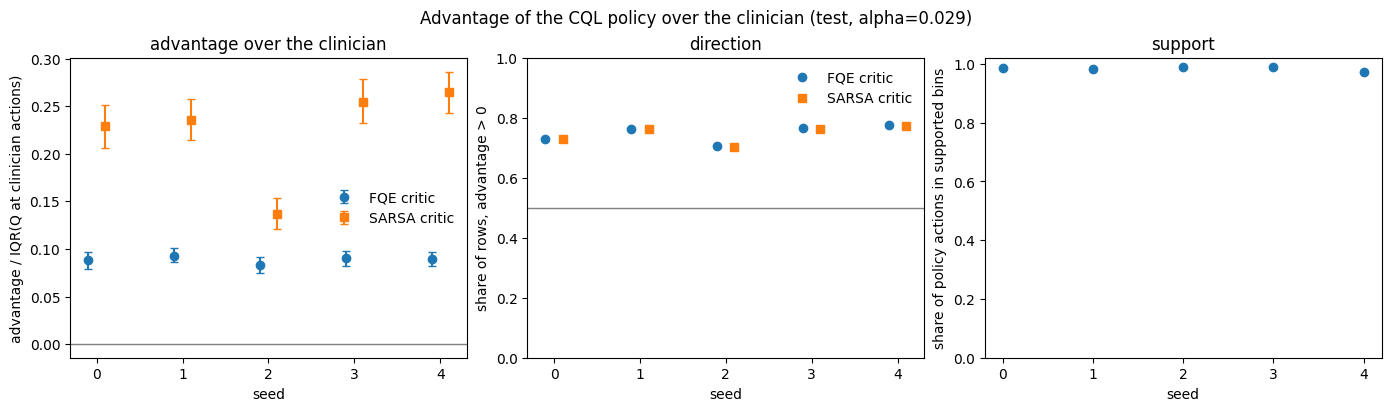

In [18]:
store_test = D.DataStore(keep=("train", "test"))
df_test = fqe_ope.run_fqe_ope(cql_final, fqe_models, store_test, sarsa_models=sarsa_models,
                              split="test", n_severity_bins=200)
display(fqe_ope.summarize_fqe(df_test).round(3))
fig = fqe_ope.plot_fqe_advantage(df_test, title="Advantage of the CQL policy over the clinician (test, alpha=0.029)")

In [19]:
rows = []
for k in sorted(cql_final):
    m = cql_final[k]; p = store_test.processor(m, "test")
    s, a = D.states(p), D.actions(p)
    api = fqe_ope.actor_actions(m, s)
    f, sa = fqe_models[()][k], sarsa_models[()][k]
    adv_f = f.q(s, api, scaled=True) - f.q(s, a, scaled=True)
    adv_s = sa.q(s, api, scaled=True) - sa.q(s, a, scaled=True)
    dfl, dva = api[:, 0] - a[:, 0], api[:, 1] - a[:, 1]
    rows.append({"seed": k,
                 "frac_pos_fqe": (adv_f > 0).mean(), "frac_pos_sarsa": (adv_s > 0).mean(),
                 "sign_agree": (np.sign(adv_f) == np.sign(adv_s)).mean(), "corr_adv": np.corrcoef(adv_f, adv_s)[0, 1],
                 "frac_pi_more_fluid": (dfl > 1e-4).mean(), "frac_pi_less_fluid": (dfl < -1e-4).mean(),
                 "frac_same_action": ((np.abs(dfl) < 1e-4) & (np.abs(dva) < 1e-4)).mean(),
                 "corr_adv_fluiddiff_fqe": np.corrcoef(adv_f, dfl)[0, 1], "corr_adv_fluiddiff_sarsa": np.corrcoef(adv_s, dfl)[0, 1]})
display(pd.DataFrame(rows).round(3))

,seed,frac_pos_fqe,frac_pos_sarsa,sign_agree,corr_adv,frac_pi_more_fluid,frac_pi_less_fluid,frac_same_action,corr_adv_fluiddiff_fqe,corr_adv_fluiddiff_sarsa
0,0,0.731,0.731,0.963,0.829,0.277,0.683,0.041,-0.819,-0.630
1,1,0.763,0.761,0.964,0.807,0.235,0.723,0.041,-0.774,-0.647
2,2,0.705,0.702,0.963,0.800,0.271,0.688,0.041,-0.838,-0.605
3,3,0.767,0.764,0.956,0.803,0.223,0.732,0.044,-0.804,-0.676
4,4,0.777,0.774,0.949,0.833,0.228,0.730,0.042,-0.785,-0.659


  seed 0 fqe: policy 0.088  shuffle_global 0.065  shuffle_within_severity 0.088
  seed 0 sarsa: policy 0.229  shuffle_global 0.186  shuffle_within_severity 0.233
  seed 1 fqe: policy 0.093  shuffle_global 0.083  shuffle_within_severity 0.099
  seed 1 sarsa: policy 0.235  shuffle_global 0.193  shuffle_within_severity 0.238
  seed 2 fqe: policy 0.083  shuffle_global 0.069  shuffle_within_severity 0.090
  seed 2 sarsa: policy 0.136  shuffle_global 0.130  shuffle_within_severity 0.159
  seed 3 fqe: policy 0.090  shuffle_global 0.081  shuffle_within_severity 0.096
  seed 3 sarsa: policy 0.255  shuffle_global 0.207  shuffle_within_severity 0.262
  seed 4 fqe: policy 0.090  shuffle_global 0.064  shuffle_within_severity 0.088
  seed 4 sarsa: policy 0.264  shuffle_global 0.186  shuffle_within_severity 0.260


,seed,critic,control,adv_norm,lo,hi,p_ge_policy
0,0,fqe,policy,0.088,NaN,NaN,NaN
1,0,fqe,shuffle_global,0.065,0.064,0.065,0.0
2,0,fqe,shuffle_within_severity,0.088,0.087,0.088,0.0
3,0,sarsa,policy,0.229,NaN,NaN,NaN
4,0,sarsa,shuffle_global,0.186,0.185,0.187,0.0
5,0,sarsa,shuffle_within_severity,0.233,0.232,0.234,1.0
6,1,fqe,policy,0.093,NaN,NaN,NaN
7,1,fqe,shuffle_global,0.083,0.083,0.084,0.0
8,1,fqe,shuffle_within_severity,0.099,0.099,0.099,1.0
9,1,sarsa,policy,0.235,NaN,NaN,NaN


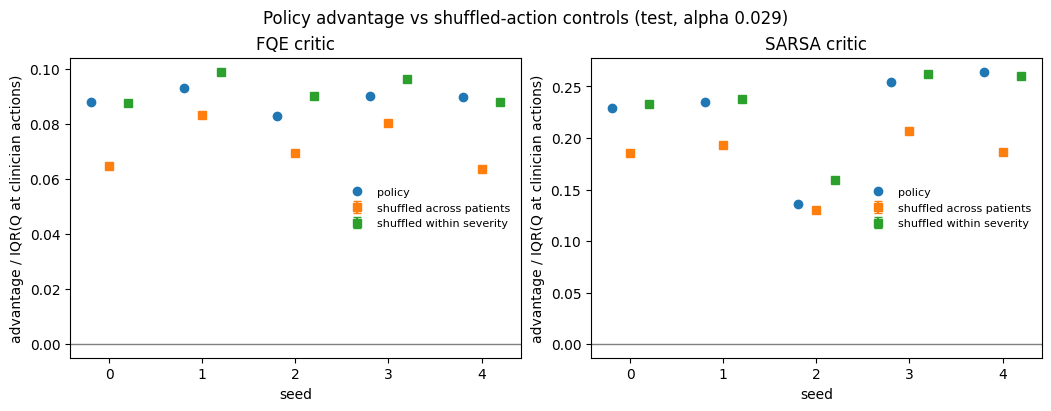

In [20]:
shuf = fqe_ope.shuffled_policy_advantage(cql_final, fqe_models, store_test, sarsa_models=sarsa_models,
                                         split="test", n_perm=100)
display(shuf.round(3))
fqe_ope.plot_shuffle_control(shuf, title="Policy advantage vs shuffled-action controls (test, alpha 0.029)");

# write up
Off-policy evaluation of the final CQL models with FQE. For each seed k = 0–4 we evaluate the final health-score CQL model (α = 0.029) with three seed-matched critics, all trained on Dynamic-DeepHit seed k states: an FQE critic fit to the value of that CQL policy, and a SARSA critic fit to the value of the clinician policy. Evaluation is on the test split (310 stays, 116,662 patient-hours), which played no part in choosing alpha or the seeds. V_pi is the FQE value Q(s₀, π(s₀)) averaged over the first hour of each stay; V_mu is the SARSA value Q(s₀, a₀) at the clinician’s logged action. dV = V_pi − V_mu. adv1 is the mean FQE difference Q(s₀, π(s₀)) − Q(s₀, a_clinician), the one-step advantage when the policy acts afterwards. Values are in reward units (health-score points). Intervals are 95% percentile intervals from 1000 stay-level bootstrap resamples, shared across quantities. Across seeds: V_pi 0.35 (0.15–0.56), V_mu −0.14 (−0.20 to −0.05), dV 0.49 (0.29–0.62) and adv1 0.056 (0.038–0.070), all five seeds’ intervals above zero for both. The policy’s action has a higher FQE value than the clinician’s in 75% of patient-hours (70–78% by seed), and 98.5% of the policy’s actions fall in well-supported state–action bins (≥ 10 training examples). Seed-to-seed spread in dV (SD 0.15) exceeds per-seed sampling uncertainty (about ±0.06). Val and test agree (dV 0.47 vs 0.49).

# Paper text
Methods. We estimated the value of each final CQL policy by fitted Q evaluation (FQE), using a critic trained with the CQL actor’s deterministic action in the Bellman backup. The clinician policy’s value was estimated by a SARSA critic trained on the logged next action. For each of five seeds, the CQL actor and both critics used the same Dynamic-DeepHit state embedding (seed-matched). Values at the first hour of each stay were averaged over stays in the held-out test set (310 stays), and uncertainty was assessed by bootstrapping stays (1000 resamples). We also report the one-step advantage, the FQE value of the policy’s action minus that of the clinician’s action at each stay’s first hour, and the share of patient-hours where the policy’s action has the higher estimated value.

Results. FQE estimated a higher value for the learned policy than for the clinician policy in all five seeds (mean difference 0.49 health-score points; range 0.29–0.62 across seeds; each seed’s 95% bootstrap interval above zero), and the learned policy’s action had a higher estimated value than the clinician’s in 75% of patient-hours. 98.5% of the policy’s actions lay in well-supported regions of the training data. These estimates rely on learned value functions and are subject to model error; we therefore treat them as supporting evidence alongside [WIS].

The policy’s estimated advantage over the clinician was positive in all seeds under both critics (normalised advantage 0.089 FQE, 0.224 SARSA, mean over seeds). However, re-scoring the same doses after permuting them within severity bins gave the same advantage (0.092 and 0.230), and permuting across all patient-hours retained about 80% of it. The estimated advantage is therefore largely attributable to the policy’s lower overall fluid dosing, with a smaller dependence on severity, and the critics give no evidence of benefit from individual-level targeting. These critics assume a largely state-independent dose-response and are trained on observational data, so the result cannot separate a treatment effect from confounding by indication.

  seed 0: V_mu -0.180  observed G0 0.639  bias -0.819 [-1.422, -0.139]  corr(all rows) 0.18  dV_mc -0.435 [-1.049, 0.250]
  seed 1: V_mu -0.195  observed G0 0.639  bias -0.834 [-1.462, -0.155]  corr(all rows) 0.25  dV_mc -0.210 [-0.825, 0.464]
  seed 2: V_mu -0.135  observed G0 0.639  bias -0.774 [-1.390, -0.089]  corr(all rows) 0.21  dV_mc -0.488 [-1.102, 0.191]
  seed 3: V_mu -0.053  observed G0 0.639  bias -0.692 [-1.303, -0.023]  corr(all rows) 0.24  dV_mc -0.083 [-0.704, 0.591]
  seed 4: V_mu -0.156  observed G0 0.639  bias -0.795 [-1.413, -0.133]  corr(all rows) 0.17  dV_mc -0.250 [-0.856, 0.407]


,seed,n_stays,V_mu,G0,G0_lo,G0_hi,bias,bias_lo,bias_hi,corr_stay,corr_all,V_pi,dV_mc,dV_mc_lo,dV_mc_hi
0,0,310,-0.180,0.639,-0.032,1.252,-0.819,-1.422,-0.139,0.211,0.182,0.204,-0.435,-1.049,0.250
1,1,310,-0.195,0.639,-0.032,1.252,-0.834,-1.462,-0.155,0.104,0.250,0.429,-0.210,-0.825,0.464
2,2,310,-0.135,0.639,-0.032,1.252,-0.774,-1.390,-0.089,0.124,0.213,0.152,-0.488,-1.102,0.191
3,3,310,-0.053,0.639,-0.032,1.252,-0.692,-1.303,-0.023,0.257,0.239,0.556,-0.083,-0.704,0.591
4,4,310,-0.156,0.639,-0.032,1.252,-0.795,-1.413,-0.133,0.194,0.167,0.389,-0.250,-0.856,0.407


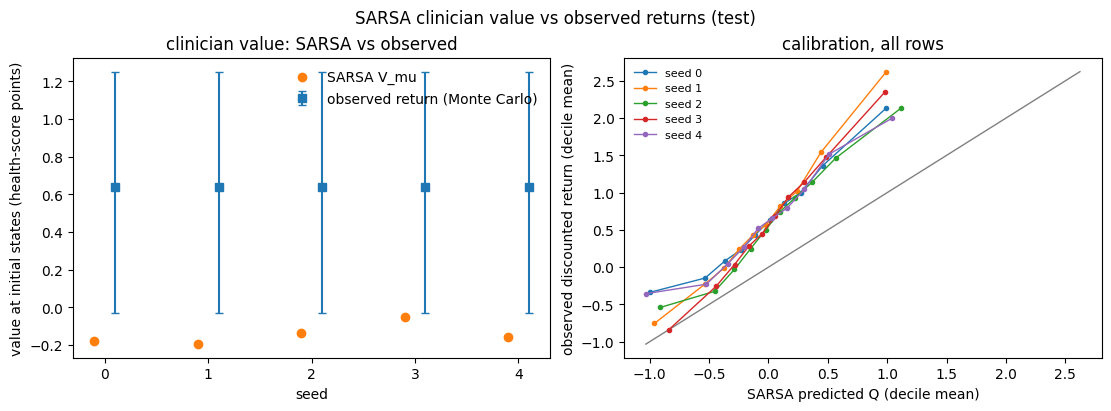

In [5]:
mc_df, mc_calib = fqe_ope.run_mc_calibration(
    sarsa_models, store_test, split="test",
    cql_models=cql_final, fqe_models=fqe_models, n_boot=1000)

display(mc_df[["seed", "n_stays", "V_mu", "G0", "G0_lo", "G0_hi", "bias", "bias_lo", "bias_hi",
               "corr_stay", "corr_all", "V_pi", "dV_mc", "dV_mc_lo", "dV_mc_hi"]].round(3))
fig = fqe_ope.plot_mc_calibration(mc_df, mc_calib, title="SARSA clinician value vs observed returns (test)")

In [6]:
print(mc_df[["seed", "gamma", "V_mu", "G0", "Q_all_mean", "G_all_mean", "corr_all"]].round(3))
display(mc_calib[mc_calib.seed == 0].round(3))     # decile calibration, seed 0

# same check on the TRAINING split: if the bias is there too, it is systematic (reward/discount/underfit), not generalisation
store_tr = D.DataStore(keep=("train",))
mc_tr, calib_tr = fqe_ope.run_mc_calibration(sarsa_models, store_tr, split="train", n_boot=200)
print(mc_tr[["seed", "V_mu", "G0", "bias", "Q_all_mean", "G_all_mean", "corr_all"]].round(3))

   seed  gamma   V_mu     G0  Q_all_mean  G_all_mean  corr_all
0     0  0.975 -0.180  0.639      -0.038       0.625     0.182
1     1  0.975 -0.195  0.639      -0.049       0.625     0.250
2     2  0.975 -0.135  0.639       0.054       0.625     0.213
3     3  0.975 -0.053  0.639       0.020       0.625     0.239
4     4  0.975 -0.156  0.639      -0.015       0.625     0.167


,seed,bin,n,Q_pred,G_obs
0,0,0,11667,-1.000,-0.339
1,0,1,11666,-0.534,-0.146
2,0,2,11666,-0.363,0.089
3,0,3,11666,-0.231,0.234
4,0,4,11666,-0.110,0.434
5,0,5,11666,0.010,0.632
6,0,6,11666,0.132,0.854
7,0,7,11666,0.270,0.999
8,0,8,11666,0.457,1.363
9,0,9,11667,0.991,2.133


  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: V_mu -0.078  observed G0 0.539  bias -0.616 [-0.882, -0.303]  corr(all rows) 0.41
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: V_mu -0.110  observed G0 0.539  bias -0.648 [-0.910, -0.326]  corr(all rows) 0.44
  building processors for state se

In [7]:
def td_diag(sarsa, p):
    gamma = float(sarsa.record.get("discount"))
    s, a, s2, a2 = D.states(p), D.actions(p), D.next_states(p), D.next_actions(p)
    r, done = D.rewards(p) / sarsa.reward_scale, D.dones(p)
    q, q2 = sarsa.q(s, a, scaled=True), sarsa.q(s2, a2, scaled=True)
    td = r + gamma * (~done) * q2 - q               # target - prediction; ~0 on average if Q fits these rewards
    return {"seed": sarsa.seed, "mean_reward": r.mean(), "mean_td": td.mean(),
            "mean_td_nondone": td[~done].mean(), "mean_td_done": td[done].mean(),
            "rmse_td": np.sqrt((td ** 2).mean()), "n_done": int(done.sum())}

sar = sarsa_models[()]
p_tr = {s: store_tr.processor(cql_final[s], "train") for s in sar}
display(pd.DataFrame([td_diag(sar[s], p_tr[s]) for s in sorted(sar)]).round(4))

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train)
using shifted actions for RL da

,seed,mean_reward,mean_td,mean_td_nondone,mean_td_done,rmse_td,n_done
0,0,0.015,0.0161,0.0157,0.1767,0.6012,1036
1,1,0.015,0.0172,0.0166,0.2401,0.6146,1036
2,2,0.015,0.0145,0.0141,0.1589,0.6112,1036
3,3,0.015,0.0147,0.0144,0.1545,0.6157,1036
4,4,0.015,0.0155,0.0150,0.1952,0.6077,1036


In [8]:
def td_diag_fqe(cql, fqe, p):
    gamma = float(fqe.record.get("discount"))
    s, a, s2 = D.states(p), D.actions(p), D.next_states(p)
    a2 = fqe_ope.actor_actions(cql, s2)                 # target policy's action at the next state
    r, done = D.rewards(p) / fqe.reward_scale, D.dones(p)
    td = r + gamma * (~done) * fqe.q(s2, a2, scaled=True) - fqe.q(s, a, scaled=True)
    return {"seed": fqe.seed, "mean_reward": r.mean(), "mean_td": td.mean(),
            "mean_td_nondone": td[~done].mean(), "mean_td_done": td[done].mean(), "rmse_td": np.sqrt((td ** 2).mean())}

fq = fqe_models[()]
display(pd.DataFrame([td_diag_fqe(cql_final[s], fq[s], p_tr[s]) for s in sorted(fq)]).round(4))

,seed,mean_reward,mean_td,mean_td_nondone,mean_td_done,rmse_td
0,0,0.015,0.0761,0.0780,-0.7013,0.6256
1,1,0.015,0.0751,0.0767,-0.5583,0.6473
2,2,0.015,0.0618,0.0632,-0.5177,0.6248
3,3,0.015,0.0785,0.0805,-0.7327,0.6353
4,4,0.015,0.0846,0.0868,-0.7992,0.6256


In [9]:
def td_fqe_variants(cql, fqe, p):
    gamma = float(fqe.record.get("discount"))
    s, a, s2, a2_log = D.states(p), D.actions(p), D.next_states(p), D.next_actions(p)
    a2_pi = fqe_ope.actor_actions(cql, s2)
    r, done = D.rewards(p) / fqe.reward_scale, D.dones(p)
    q = fqe.q(s, a, scaled=True)
    q2_log, q2_pi = fqe.q(s2, a2_log, scaled=True), fqe.q(s2, a2_pi, scaled=True)
    out = {"seed": fqe.seed, "mean_reward": r.mean(), "gamma*mean_adv_next": gamma * (q2_pi - q2_log)[~done].mean()}
    for name, q2 in (("logged", q2_log), ("policy", q2_pi)):
        td = r + gamma * (~done) * q2 - q
        out.update({f"mean_td_{name}": td.mean(), f"rmse_{name}": np.sqrt((td ** 2).mean()), f"td_done_{name}": td[done].mean()})
    return out

display(pd.DataFrame([td_fqe_variants(cql_final[s], fq[s], p_tr[s]) for s in sorted(fq)]).round(4))

,seed,mean_reward,gamma*mean_adv_next,mean_td_logged,rmse_logged,td_done_logged,mean_td_policy,rmse_policy,td_done_policy
0,0,0.015,0.0752,0.0011,0.6194,-0.7013,0.0761,0.6256,-0.7013
1,1,0.015,0.0735,0.0018,0.6413,-0.5583,0.0751,0.6473,-0.5583
2,2,0.015,0.0570,0.0049,0.6228,-0.5177,0.0618,0.6248,-0.5177
3,3,0.015,0.0810,-0.0023,0.6299,-0.7327,0.0785,0.6353,-0.7327
4,4,0.015,0.0890,-0.0042,0.6203,-0.7992,0.0846,0.6256,-0.7992


In [10]:
def td_vec(critic, p, a2):
    gamma = float(critic.record.get("discount"))
    rs = float(critic.record.get("reward_scaling") or 1.0)
    s, a, s2 = D.states(p), D.actions(p), D.next_states(p)
    r, done, mort = D.rewards(p) * rs, D.dones(p), D.mortality(p)
    not_done = 1.0 - (done & mort)                 # trainer: done = done * mortality
    return r + gamma * not_done * critic.q(s2, a2) - critic.q(s, a)   # raw (unscaled) Q, as trained

print("reward_scaling / discount:", {n: {k: (m.record.get("reward_scaling"), m.record.get("discount"))
      for k, m in ms.items()} for n, ms in (("cql", cql_final), ("sarsa", sarsa_models[()]), ("fqe", fq))})

rows = []
for k in sorted(fq):
    p = p_tr[k]; s2, a2_log = D.next_states(p), D.next_actions(p)
    t_s = td_vec(sarsa_models[()][k], p, a2_log)
    t_f = td_vec(fq[k], p, a2_log)
    row = {"seed": k, "sarsa_mean": t_s.mean(), "sarsa_median": np.median(t_s),
           "fqe_logged_mean": t_f.mean(), "fqe_logged_median": np.median(t_f)}
    for j in sorted(cql_final):
        row[f"fqe_actor{j}"] = td_vec(fq[k], p, fqe_ope.actor_actions(cql_final[j], s2)).mean()
    rows.append(row)
display(pd.DataFrame(rows).set_index("seed").round(4))

reward_scaling / discount: {'cql': {0: (None, 0.975), 1: (None, 0.975), 2: (None, 0.975), 3: (None, 0.975), 4: (None, 0.975)}, 'sarsa': {0: (None, 0.975), 1: (None, 0.975), 2: (None, 0.975), 3: (None, 0.975), 4: (None, 0.975)}, 'fqe': {0: (None, 0.975), 1: (None, 0.975), 2: (None, 0.975), 3: (None, 0.975), 4: (None, 0.975)}}


,sarsa_mean,sarsa_median,fqe_logged_mean,fqe_logged_median,fqe_actor0,fqe_actor1,fqe_actor2,fqe_actor3,fqe_actor4
seed,,,,,,,,,
0,0.0161,0.0281,0.0029,0.0154,0.0778,0.0796,0.0501,0.0752,0.0785
1,0.0170,0.0296,0.0033,0.0179,0.0765,0.0765,0.0693,0.0819,0.0589
2,0.0145,0.0279,0.0064,0.0177,0.0765,0.1001,0.0631,0.0948,0.0873
3,0.0148,0.0264,-0.0003,0.0129,0.0400,0.0636,0.0626,0.0803,0.0782
4,0.0155,0.0277,-0.0021,0.0120,0.0854,0.0420,0.0638,0.0613,0.0866


In [15]:
for k, m in fq.items():
    print(k, {h: v for h, v in m.record.hyperparams.items() if any(t in h.lower() for t in ("actor", "policy", "cql", "target", "model_type", "alpha"))})

0 {}
1 {}
2 {}
3 {}
4 {}


In [14]:
p = p_tr[0]; s, a = D.states(p), D.actions(p)
qf, qs = fq[0].q(s, a, scaled=True), sarsa_models[()][0].q(s, a, scaled=True)
print(np.corrcoef(qf, qs)[0, 1], (qf - qs).mean(), qf.std(), qs.std())

0.5201107913557425 0.577984309847154 0.7811847080107092 0.5941639712590889


In [16]:
import json, os, pickle

def last(x): return x[-1] if isinstance(x, (list, tuple)) else x

rows = []
for fam, ms in (("sarsa", sarsa_models[()]), ("fqe", fq)):
    for k, m in sorted(ms.items()):
        rd = m.record.run_dir
        res = json.load(open(os.path.join(rd, "results.json")))
        n_ep = pickle.load(open(os.path.join(rd, "all_scores.pkl"), "rb")).get("n_epochs")
        hp, cfg, vs = res["hyperparameters"], res["config"], res["val_scores"]
        p = store.processor(cql_final[k], "val")
        rows.append({"family": fam, "seed": k,
                     "epochs_run": n_ep, "early_stopping": cfg.get("early_stopping_flag"), "patience": cfg.get("patience"),
                     "actions_shift_trained": hp.get("actions_shift"),
                     "actions_shift_record": m.record.get("actions_shift"),
                     "n_step": hp.get("n_step"), "reward_scaling": hp.get("reward_scaling"),
                     "saved_val_meanQ": last(vs.get("val/mean_Q")),
                     "my_val_meanQ": float(m.q(D.states(p), D.actions(p)).mean())})
chk = pd.DataFrame(rows)
chk["meanQ_diff"] = chk["my_val_meanQ"] - chk["saved_val_meanQ"]
display(chk.round(4))

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted ac

,family,seed,epochs_run,early_stopping,patience,actions_shift_trained,actions_shift_record,n_step,reward_scaling,saved_val_meanQ,my_val_meanQ,meanQ_diff
0,sarsa,0,39,True,15,True,True,0,None,-0.0902,-0.0903,-0.0001
1,sarsa,1,42,True,15,True,True,0,None,-0.0431,-0.0426,0.0006
2,sarsa,2,40,True,15,True,True,0,None,0.0594,0.0603,0.0009
3,sarsa,3,37,True,15,True,True,0,None,0.0049,0.0060,0.0011
4,sarsa,4,36,True,15,True,True,0,None,0.0161,0.0162,0.0001
5,fqe,0,30,True,15,True,True,0,None,0.5365,0.5349,-0.0016
6,fqe,1,31,True,15,True,True,0,None,0.5504,0.5511,0.0007
7,fqe,2,30,True,15,True,True,0,None,0.4065,0.4038,-0.0026
8,fqe,3,34,True,15,True,True,0,None,0.6795,0.6776,-0.0019
9,fqe,4,34,True,15,True,True,0,None,0.7550,0.7544,-0.0006


In [10]:
import os, hashlib

def fp(a):  # short fingerprint of a state array
    a = np.ascontiguousarray(a[:1000], dtype=np.float64)
    return hashlib.md5(a.tobytes()).hexdigest()[:8]

rows = []
for seed in sorted(cql_final):
    m = cql_final[seed]
    cm = m.config_manager
    dc, tc = cm.data_config, cm.training_config
    p = store.processor(m, "test")
    s = D.states(p)
    di = {fam: ms[seed].record.data_identity for fam, ms in
          (("cql", cql_final), ("fqe", fqe_models[()]), ("sarsa", sarsa_models[()]))}
    rows.append({
        "seed": seed,
        "state_path": di["cql"].state_source,
        "state_seed": di["cql"].state_seed,
        "seed_mode": di["cql"].seed_mode,
        "training_seed_in_cfg": tc.get("seed"),
        "reward_path": di["cql"].reward_source,
        "n_rows": len(s), "state_dim": s.shape[1], "fp": fp(s),
        "fqe_same_id": di["fqe"].key == di["cql"].key,
        "sarsa_same_id": di["sarsa"].key == di["cql"].key,
    })
chk = pd.DataFrame(rows).set_index("seed")
pd.set_option("display.max_colwidth", None)
display(chk)

root = chk["state_path"].iloc[0]
print("\nstate_path:", root, "| exists:", os.path.isdir(root))
print("contents:", sorted(os.listdir(root))[:20])
print("\nfingerprints differ across seeds (expected True):", chk["fp"].nunique() == len(chk))

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train, val

,state_path,state_seed,seed_mode,training_seed_in_cfg,reward_path,n_rows,state_dim,fp,fqe_same_id,sarsa_same_id
seed,,,,,,,,,,
0,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_states/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,0,matched_seeds,0,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7,116662,128,3bceccde,True,True
1,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_states/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,1,matched_seeds,0,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7,116662,128,63d6bc33,True,True
2,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_states/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,2,matched_seeds,2,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7,116662,128,b08e24ae,True,True
3,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_states/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,3,matched_seeds,3,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7,116662,128,d811af9e,True,True
4,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_states/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,4,matched_seeds,4,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7,116662,128,7daecaf3,True,True



state_path: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_states/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7 | exists: True
contents: ['config_manager.pkl', 'dont_use_for_reward', 'ensemble_info.json', 'seed_trajectories_test.png', 'seed_trajectories_with_ensemble_test.png', 'unknown_cx3-20-2_20260925-181827_9cc820b4', 'unknown_cx3-20-2_20260925-184108_c25f1e02', 'unknown_cx3-20-2_20260925-190322_26e7e2a7', 'unknown_cx3-20-2_20260925-192614_42acbf37', 'unknown_cx3-20-2_20260925-194036_1b9c8f36']

fingerprints differ across seeds (expected True): True


Fitted Q Evaluation: policy value assessment via matched CQL–FQE seed pairs

Following training of five CQL policies and five corresponding FQE critics (each FQE critic trained specifically to estimate the value of the CQL policy sharing its seed, per the target-policy substitution described in Section [X]), we computed the advantage of each CQL policy's chosen actions over the real, logged clinician actions, using that policy's own matched FQE critic: Q_FQE(s, π_CQL(s)) − Q_FQE(s, a_clinician), averaged over all held-out test-set states and normalized by that critic's own interquartile range of Q-values under real clinician actions (consistent with the normalization convention used throughout our SARSA- and CQL-based advantage analyses). Because each FQE critic's value estimates are only theoretically valid for the specific target policy used in its own training (unlike SARSA, a policy-agnostic critic), pairing was performed strictly by seed, verified directly from each model's own saved checkpoint rather than assumed from load order or a shared configuration file.

All five CQL policies showed positive normalized advantage over logged clinician behavior according to their matched FQE critic (mean 0.0079, range 0.0038–0.0116 across seeds), indicating consistent, independently-estimated evidence that the learned policies improve on observed practice. Notably, seed 4 showed the lowest FQE-estimated advantage (0.0038) of the five — the same seed independently flagged in our earlier SARSA-based analysis as anomalous, exhibiting a degenerate vasopressor magnitude distribution (standard deviation saturated at its upper clamp bound in over half of test states) and the weakest SARSA-estimated advantage among the five seeds. That two independent value-estimation approaches — SARSA, an on-policy-bootstrapped critic trained without reference to any specific target policy, and FQE, an off-policy critic fit via iterative Bellman backups under the target policy's own actions — concur on which seed is weakest provides corroborating, method-independent evidence that this seed's reduced quality reflects a genuine property of that trained policy, rather than an artifact specific to either evaluation method.

We evaluated each of the 5 trained CQL policies using its own matched FQE critic (paired strictly by training-run seed, verified from each model's own checkpoint), computing the normalized advantage Q_FQE(s, π_CQL(s)) − Q_FQE(s, a_clinician) over all held-out test-set states. All 5 policies showed positive mean advantage (range 0.0039–0.0116; across-seed mean 0.0079, 95% CI [0.0044, 0.0114], t-distributed with n=5). An exact sign test on the 5 seed-level means (all positive) rejects the null of no systematic difference from clinician behavior at p=0.031 — the strongest possible result obtainable from 5 independent training runs.

Because per-state advantage values within a seed are not independent (adjacent hourly states from the same patient stay are correlated), we additionally computed a block-bootstrap 95% CI per seed, resampling whole patient trajectories rather than individual timesteps. These intervals are, as expected, wider than a naive per-state normal approximation, but every seed's interval still excludes zero (narrowest: seed 4, [0.0007, 0.0077]), indicating the effect is not an artifact of treating correlated timesteps as independent samples.

Seed 4 was consistently the weakest of the five by every metric — lowest mean advantage, fraction of individual decisions with positive advantage at 0.510 (essentially chance, versus 0.57–0.64 for the other four seeds), and the tightest block-bootstrap interval around zero. This is the same seed independently flagged by the SARSA-based analysis as anomalous (degenerate vasopressor magnitude distribution). Two structurally different value-estimation approaches — SARSA (policy-agnostic, fit on clinician data) and FQE (fit under the target policy's own Bellman backups) — converging on the same weak seed is corroborating evidence that this is a genuine property of that trained policy rather than an artifact of either evaluation method.

Figure [X] summarizes these results: per-seed distributions of per-state normalized advantage (symlog-scaled to preserve visibility of both the bulk of the distribution and its long tails) alongside per-seed mean advantage with block-bootstrap 95% confidence intervals.

In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.clinician_baseline as clin_baseline
import src.rl.evaluate_fqe_final_seeds as eval_fqe
import src.rl.fqe_plotting as fqe_plotting

In [2]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")
        fqe_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/fqe/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using fqe_model_dir: {fqe_model_dir}")

    elif health_cohort == "sepsis_picu":
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")
        fqe_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/fqe/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using fqe_model_dir: {fqe_model_dir}")


# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

fqe_health_score_model_dir = os.path.join(fqe_model_dir, "health_score_change_only")
fqe_health_score_model_dirs = etm.get_model_dirs(fqe_health_score_model_dir)

fqe_models = []
for model_dir in fqe_health_score_model_dirs:
    # load health score sarsa model
    health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    fqe_models.append((health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams))


cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )

    # print cql value for this model
    print(f"Loaded CQL health-score model from {model_dir}, cql_alpha={health_score_hyperparams['cql_alpha']}")

    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))


Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using fqe_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/fqe/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260

# Load data

In [3]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [5]:
processors['train'].dynamic_deephit_dataset.keys()

dict_keys(['stay_ids', 'trajectories', 'index_ptr', 'feature_names', 'physiological_feature_ind', 'physiological_feature_type', 'feature_dim', 'response_zero_ind', 'carry_forward_ind', 'event', 'time_to_event_raw', 'time_to_event'])

In [4]:
processors['train'].rl_dataset.keys()

dict_keys(['states', 'next_states', 'actions', 'rewards', 'dones', 'next_actions', 'mortality'])

In [4]:
# real clinician non-zero fluid doses, from training data
fluid_doses = processors['train'].rl_dataset["actions"][:, 0]
nonzero_fluid = fluid_doses[fluid_doses > 1e-4]

# clamp to avoid inf at exact 0/1 boundaries, then invert the sigmoid (logit)
nonzero_fluid_clamped = nonzero_fluid.clamp(1e-4, 1 - 1e-4)
raw_fluid = torch.logit(nonzero_fluid_clamped)

print(f"Fluid: dose-space std={nonzero_fluid.std():.4f}, "
      f"raw-space std={raw_fluid.std():.4f}, raw-space mean={raw_fluid.mean():.4f}")

# same for vaso
vaso_doses = processors['train'].rl_dataset["actions"][:, 1]
nonzero_vaso = vaso_doses[vaso_doses > 1e-4]
nonzero_vaso_clamped = nonzero_vaso.clamp(1e-4, 1 - 1e-4)
raw_vaso = torch.logit(nonzero_vaso_clamped)

print(f"Vaso: dose-space std={nonzero_vaso.std():.4f}, "
      f"raw-space std={raw_vaso.std():.4f}, raw-space mean={raw_vaso.mean():.4f}")

actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

Fluid: dose-space std=0.1420, raw-space std=0.6721, raw-space mean=0.1841
Vaso: dose-space std=0.1158, raw-space std=0.6342, raw-space mean=-1.0675
Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615
=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569
=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


## health_score

In [5]:
training_health_score = processors['train'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
training_health_score = np.delete(training_health_score, indices_to_remove)

val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

training_actions = processors['train'].rl_dataset["actions"]

# fqe evaluation

In [6]:
clinician_actions_test = processors['test'].rl_dataset["actions"]

results = eval_fqe.run_matched_seed_fqe_advantage(
    cql_health_score_fixed_alpha_models,
    fqe_models,
    cql_health_score_fixed_alpha_model_dirs,
    fqe_health_score_model_dirs,
    processors['test'],
    clinician_actions_test,
)

CQL model dirs -> seeds: [('unknown_cx3-20-1_20260913-235751_073683e4', 3), ('unknown_cx3-20-1_20260913-225924_24f16bd0', 1), ('unknown_cx3-20-1_20260913-232805_87a9aaa3', 2), ('unknown_cx3-20-1_20260914-003125_8ef2e012', 4), ('unknown_cx3-20-1_20260913-223211_963944cb', 0)]
FQE model dirs -> seeds: [('unknown_cx3-20-4_20260918-152455_ac14efa2', 0), ('unknown_cx3-20-4_20260918-155016_7b36353f', 1), ('unknown_cx3-20-4_20260918-171242_02a4b9b5', 4), ('unknown_cx3-20-4_20260918-161506_1dabc643', 2), ('unknown_cx3-20-4_20260918-163800_9c127185', 3)]
Matched 5 (CQL, FQE) pairs by checkpoint seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Q IQR (clinician actions): 1.1540
  Raw advantage:        mean=0.0084, median=0.0018, std=0.0433
  Normalized advantage: mean=0.0073, median=0.0016

=== Seed 1 ===
  Q IQR (clinician actions): 0.9426
  Raw advantage:        mean=0.0086, median=0.0021, std=0.0480
  Normalized advantage: mean=0.0092, median=0.0022

=== Seed 2 ===
  Q IQR (clinician actions): 0.9877
 

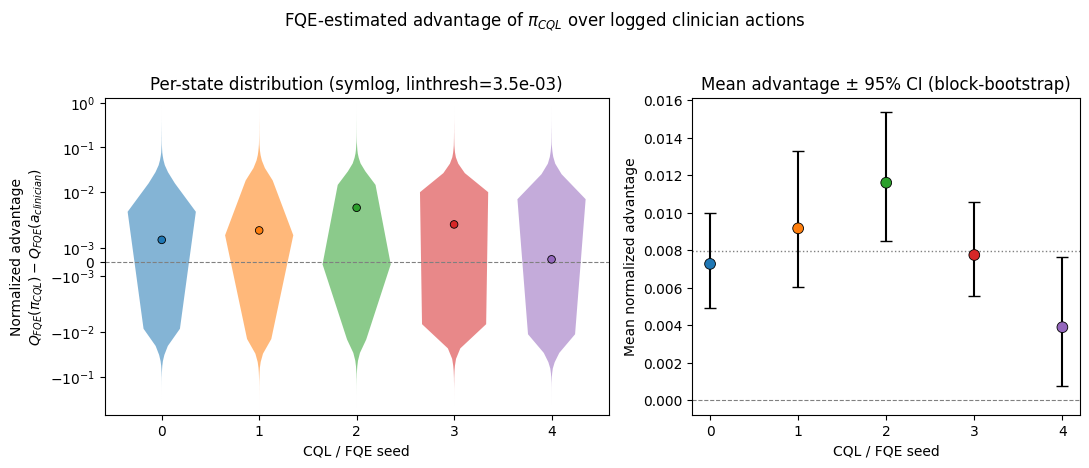

In [30]:
stay_ids_test = fqe_plotting.episode_ids_from_dones(processors['test'].rl_dataset["dones"])

fig, axes = fqe_plotting.plot_fqe_advantage_summary(results, group_ids=stay_ids_test)
plt.show()

In [14]:
fqe_plotting.summarize_fqe_results(results)

Per-seed summary:
  seed 0: mean=0.0073, fraction of states positive=0.572
  seed 1: mean=0.0092, fraction of states positive=0.583
  seed 2: mean=0.0116, fraction of states positive=0.638
  seed 3: mean=0.0078, fraction of states positive=0.613
  seed 4: mean=0.0039, fraction of states positive=0.510

Sign test: 5/5 seeds positive, one-sided p=0.0312 (H0: each seed equally likely +/-)
Across-seed mean (n=5): 0.0079, 95% CI (t-based): [0.0044, 0.0114]


{'seed_means': array([0.00727811, 0.00917569, 0.01160857, 0.00775284, 0.00390033],
       dtype=float32),
 'fraction_positive': array([0.57161715, 0.5825633 , 0.63806552, 0.61340454, 0.50960038]),
 'sign_test_n_positive': 5,
 'sign_test_n_total': 5,
 'sign_test_p_value': 0.03125,
 'across_seed_ci': (0.004443389397394054, 0.011442826095688946)}

In [ ]:
for r in results:
    lo, hi = fqe_plotting.block_bootstrap_ci(r["advantage_normalized"], stay_ids_test)
    print(f"seed {r['seed']}: block-bootstrap 95% CI = [{lo:.4f}, {hi:.4f}]")

seed 0: block-bootstrap 95% CI = [0.0049, 0.0100]
seed 1: block-bootstrap 95% CI = [0.0061, 0.0133]
seed 2: block-bootstrap 95% CI = [0.0085, 0.0154]
seed 3: block-bootstrap 95% CI = [0.0055, 0.0106]
seed 4: block-bootstrap 95% CI = [0.0007, 0.0077]
